
# RQ2 — ESRS Context Ablation

This notebook analyzes **Research Question 2** using the remediated paired ablation design:

- `with_esrs_context`
- `without_esrs_context`

The treatment condition injects the **substantive full mapped ESRS standard** for each question. The control condition keeps the same question, the same retrieval output, the same ESRS metadata, and the same prompt structure, but injects an empty ESRS context block. All persisted artifacts are validated against the current repository state before any thesis claim is made.


## 1. Environment, Paths, and Current Experiment Definition

In [ ]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'rag').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from rag.config.settings import (
    RQ2_CONTEXT_MODE,
    RQ2_RESULTS_DIR,
    build_rq2_audit_manifest,
    load_best_pipeline_config,
)
from rag.data.loaders import load_generation_samples
from rag.evaluation.rq2_metrics import (
    build_context_summary,
    build_question_manifest,
    validate_rq2_artifacts,
)
from rag.generation.esrs_context import ESRSContextExtractor
from rag.pipeline.rq2_runner import RQ2PipelineRunner

RESULTS_DIR = RQ2_RESULTS_DIR / RQ2_CONTEXT_MODE
SUMMARY_PATH = RESULTS_DIR / "rq2_summary.json"
SAMPLE_RESULTS_PATH = RESULTS_DIR / "rq2_sample_results.csv"
PAIRED_RESULTS_PATH = RESULTS_DIR / "rq2_paired_results.csv"
QUESTION_RESULTS_PATH = RESULTS_DIR / "rq2_question_level_results.csv"

best_config = load_best_pipeline_config()
samples = load_generation_samples()
question_manifest = build_question_manifest(samples)
audit_manifest = build_rq2_audit_manifest()

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_columns", 50)

print(f"RQ2 context mode: {RQ2_CONTEXT_MODE}")
print(f"Results directory: {RESULTS_DIR}")
print(f"Best pipeline from RQ1: {best_config.get('_best_pipeline_name', 'unknown')}")

In [2]:

manifest_df = pd.DataFrame(question_manifest)
display(manifest_df[[
    "question_id",
    "esrs_standard",
    "esrs_disclosure_id",
    "resolved_titles",
    "missing_disclosure_ids",
    "ok",
]])

if not manifest_df["ok"].all():
    raise ValueError("Question-to-ESRS mapping audit failed. Fix the manifest before analysing RQ2.")


,question_id,esrs_standard,esrs_disclosure_id,resolved_titles,missing_disclosure_ids,ok
0,Q1,ESRS 2,"IRO-1, SBM-3","[Disclosure Requirement IRO-1 - Description of the process to identify and assess material impacts, risks and opportunities, Disclosure Requirement SBM-3 - ...",[],True
1,Q2,ESRS 2,GOV-3,[Disclosure Requirement GOV-3 – Integration of sustainability-related performance in incentive schemes],[],True
2,Q3,ESRS E1,E1-1,[Disclosure Requirement E1-1 – Transition plan for climate change mitigation],[],True
3,Q4,ESRS E2,E2-4,"[Disclosure Requirement E2-4 – Pollution of air, water and soil]",[],True
4,Q5,ESRS E3,E3-4,[Disclosure Requirement E3-4 – Water consumption],[],True
5,Q6,ESRS E4,"E4-3, E4-5","[Disclosure Requirement E4-3 – Actions and resources related to biodiversity and ecosystems, Disclosure Requirement E4-5 – Impact metrics related to biodive...",[],True
6,Q7,ESRS E5,E5-5,[Disclosure Requirement E5-5 – Resource outflows],[],True
7,Q8,ESRS S1,"S1-6, S1-9","[Disclosure Requirement S1-6 – Characteristics of the undertaking’s employees, Disclosure Requirement S1-9 – Diversity metrics]",[],True
8,Q9,ESRS S2,"S2-1, S2-2","[Disclosure Requirement S2-1 – Policies related to value chain workers, Disclosure Requirement S2-2 – Processes for engaging with value chain workers about ...",[],True
9,Q10,ESRS S3,"S3-2, S3-3","[Disclosure Requirement S3-2 – Processes for engaging with affected communities about impacts, Disclosure Requirement S3-3 – Processes to remediate negative...",[],True


## 2. Offline ESRS Context Audit

In [ ]:
extractor = ESRSContextExtractor(cache_path=RESULTS_DIR / "context_cache.json", require_openai=False)
question_samples = {}
for sample in samples:
    question_samples.setdefault(sample.question_id, sample)

context_results = {
    question_id: extractor.get_or_extract(sample)
    for question_id, sample in sorted(question_samples.items())
}
context_df = pd.DataFrame(build_context_summary(context_results))
context_df = context_df.sort_values("question_id").reset_index(drop=True)

display(context_df[[
    "question_id",
    "esrs_standard",
    "esrs_disclosure_id",
    "included_section_count",
    "estimated_tokens",
    "character_count",
]])

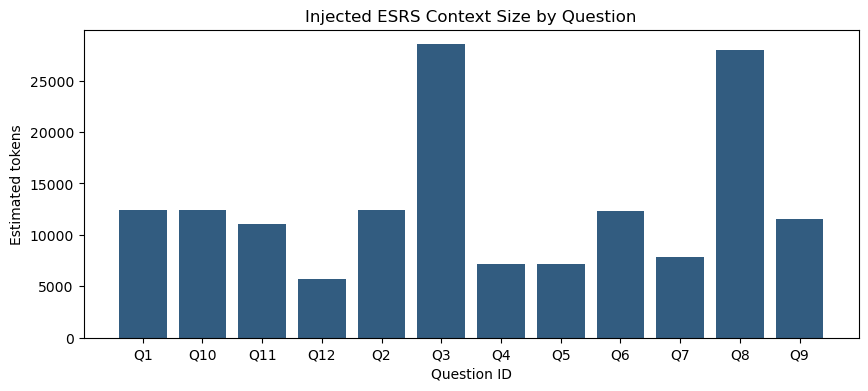

In [4]:

fig, ax = plt.subplots(figsize=(10, 4))
plot_df = context_df.sort_values("question_id")
ax.bar(plot_df["question_id"], plot_df["estimated_tokens"], color="#325c80")
ax.set_title("Injected ESRS Context Size by Question")
ax.set_ylabel("Estimated tokens")
ax.set_xlabel("Question ID")
plt.show()


## 3. Execute or Resume the Paired RQ2 Experiment

In [ ]:
# Set RUN_PIPELINE = True to execute or resume the 408 generation calls.
# With RUN_PIPELINE = False, only pre-computed artifacts are loaded.
RUN_PIPELINE = False
DRY_RUN = False
QUESTION_ID = None
COMPANY = None
CONDITION_PARALLELISM = 1

if RUN_PIPELINE:
    runner = RQ2PipelineRunner(
        dry_run=DRY_RUN,
        question_id=QUESTION_ID,
        company=COMPANY,
        condition_parallelism=CONDITION_PARALLELISM,
        results_dir=RESULTS_DIR,
    )
    _ = runner.run()
    print("RQ2 run completed.")
else:
    print("RUN_PIPELINE is False; loading persisted artifacts only.")

## 4. Load Persisted Artifacts and Fail Closed on Stale Results

In [6]:

summary = json.loads(SUMMARY_PATH.read_text(encoding="utf-8"))
sample_results = pd.read_csv(SAMPLE_RESULTS_PATH)
paired_results = pd.read_csv(PAIRED_RESULTS_PATH)
question_results = pd.read_csv(QUESTION_RESULTS_PATH)

validate_rq2_artifacts(
    summary_payload=summary,
    sample_rows=sample_results.to_dict(orient="records"),
    paired_rows=paired_results.to_dict(orient="records"),
    question_rows=question_results.to_dict(orient="records"),
    expected_audit_manifest=audit_manifest,
    expected_question_manifest=question_manifest,
)

print("Artifact validation passed.")
print(f"Samples: {len(sample_results)} rows")
print(f"Pairs: {len(paired_results)} rows")
print(f"Questions: {len(question_results)} rows")


Artifact validation passed.
Samples: 408 rows
Pairs: 204 rows
Questions: 12 rows


## 5. Aggregate Classification Results

In [7]:

aggregate_df = pd.DataFrame(summary["aggregate_metrics"]).T[[
    "macro_f1",
    "balanced_accuracy",
    "exact_accuracy",
    "weighted_kappa",
    "ordinal_error_mean",
    "direct_answer_token_f1",
    "rationale_token_f1",
    "evidence_support_ratio",
    "n_scored",
    "n_failures",
]].round(4)
aggregate_df


,macro_f1,balanced_accuracy,exact_accuracy,weighted_kappa,ordinal_error_mean,direct_answer_token_f1,rationale_token_f1,evidence_support_ratio,n_scored,n_failures
with_esrs_context,0.604011,0.605246,0.745098,0.540239,0.269608,0.474248,0.317779,0.968499,204,0
without_esrs_context,0.582098,0.579413,0.766169,0.557464,0.248756,0.478365,0.325029,0.96859,201,3


## 6. Primary Confirmatory Inference

In [8]:

paired_stats = summary["paired_statistics"]
cluster_bootstrap = pd.DataFrame.from_dict(paired_stats["cluster_bootstrap"], orient="index")
question_tests = pd.DataFrame.from_dict(paired_stats["question_level_tests"], orient="index")

classification_metrics = [
    "macro_f1",
    "balanced_accuracy",
    "exact_accuracy",
    "weighted_kappa",
    "ordinal_error_mean",
]

cluster_view = cluster_bootstrap.loc[classification_metrics, [
    "mean_delta",
    "ci_lower",
    "ci_upper",
    "approx_two_sided_p",
    "n_question_clusters",
]].round(4)
question_test_view = question_tests.loc[classification_metrics, [
    "mean_with",
    "mean_without",
    "mean_delta",
    "median_delta",
    "p_value",
    "effect_size",
    "direction",
    "endpoint_role",
]].round(4)

primary_metric = "macro_f1"
primary_ci = paired_stats["cluster_bootstrap"][primary_metric]
primary_test = paired_stats["question_level_tests"][primary_metric]

print("Primary endpoint: question-level macro-F1 delta")
display(cluster_view)
display(question_test_view)


Primary endpoint: question-level macro-F1 delta


,mean_delta,ci_lower,ci_upper,approx_two_sided_p,n_question_clusters
macro_f1,-0.0110,-0.0394,0.0175,0.4715,12
balanced_accuracy,0.0042,-0.0327,0.0457,0.8250,12
exact_accuracy,-0.0209,-0.0585,0.0134,0.2680,12
weighted_kappa,-0.0357,-0.0986,0.0230,0.2560,12
ordinal_error_mean,0.0209,-0.0134,0.0585,0.2625,12


,mean_with,mean_without,mean_delta,median_delta,p_value,effect_size,direction,endpoint_role
macro_f1,0.4783,0.4893,-0.0110,0.0,0.4980,-0.1911,higher_is_better,confirmatory_primary
balanced_accuracy,0.6843,0.6802,0.0042,0.0,0.8438,0.0496,higher_is_better,supportive_classification
exact_accuracy,0.7451,0.7660,-0.0209,0.0,0.3438,-0.2748,higher_is_better,supportive_classification
weighted_kappa,0.4830,0.5187,-0.0357,0.0,0.2930,-0.2775,higher_is_better,supportive_classification
ordinal_error_mean,0.2696,0.2487,0.0209,0.0,0.3438,0.2748,lower_is_better,supportive_classification


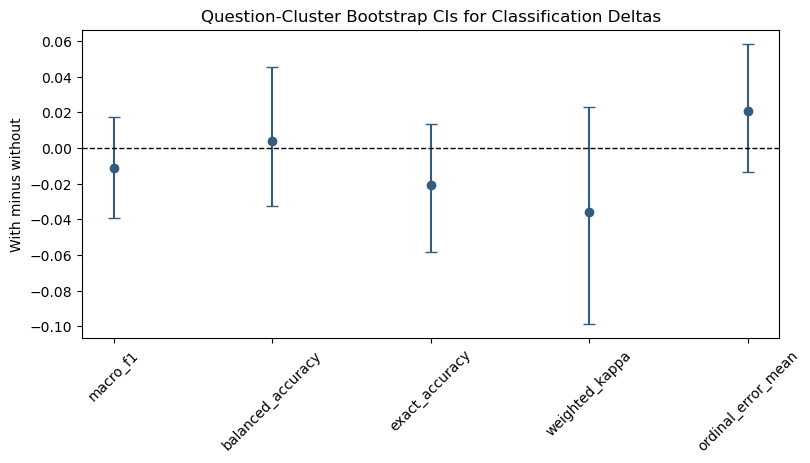

In [9]:

fig, ax = plt.subplots(figsize=(9, 4))
plot_df = cluster_view.reset_index().rename(columns={"index": "metric"})
ax.errorbar(
    plot_df["metric"],
    plot_df["mean_delta"],
    yerr=[plot_df["mean_delta"] - plot_df["ci_lower"], plot_df["ci_upper"] - plot_df["mean_delta"]],
    fmt="o",
    capsize=4,
    color="#325c80",
)
ax.axhline(0.0, color="black", linewidth=1, linestyle="--")
ax.set_title("Question-Cluster Bootstrap CIs for Classification Deltas")
ax.set_ylabel("With minus without")
ax.tick_params(axis="x", rotation=45)
plt.show()


## 7. Question-Level Delta Table

In [10]:

question_delta_view = question_results[[
    "question_id",
    "esrs_standard",
    "esrs_disclosure_id",
    "macro_f1__with_esrs_context",
    "macro_f1__without_esrs_context",
    "macro_f1_delta",
    "balanced_accuracy_delta",
    "exact_accuracy_delta",
    "weighted_kappa_delta",
    "ordinal_error_mean_delta",
]].sort_values("macro_f1_delta", ascending=False).round(4)
question_delta_view


,question_id,esrs_standard,esrs_disclosure_id,macro_f1__with_esrs_context,macro_f1__without_esrs_context,macro_f1_delta,balanced_accuracy_delta,exact_accuracy_delta,weighted_kappa_delta,ordinal_error_mean_delta
6,Q7,ESRS E5,E5-5,0.6522,0.5833,0.0688,0.1583,0.0588,0.0816,-0.0588
7,Q8,ESRS S1,"S1-6, S1-9",0.5317,0.4868,0.0450,0.0357,0.0588,0.1321,-0.0588
1,Q2,ESRS 2,GOV-3,0.4061,0.3611,0.0449,0.0833,0.0000,0.0552,0.0000
0,Q1,ESRS 2,"IRO-1, SBM-3",0.2759,0.2667,0.0092,0.0392,0.0392,0.0000,-0.0392
11,Q12,ESRS G1,"G1-3, G1-4",0.5448,0.5441,0.0007,0.0000,0.0037,0.0019,-0.0037
8,Q9,ESRS S2,"S2-1, S2-2",0.5432,0.5432,0.0000,0.0000,0.0000,0.0000,0.0000
10,Q11,ESRS S4,S4-1,0.2556,0.2556,0.0000,0.0000,0.0000,0.0000,0.0000
9,Q10,ESRS S3,"S3-2, S3-3",0.4061,0.4380,-0.0319,-0.0303,-0.0588,-0.0865,0.0588
5,Q6,ESRS E4,"E4-3, E4-5",0.4778,0.5156,-0.0378,-0.0417,-0.0588,-0.1153,0.0588
2,Q3,ESRS E1,E1-1,0.4868,0.5317,-0.0450,-0.0385,-0.0588,-0.1415,0.0588


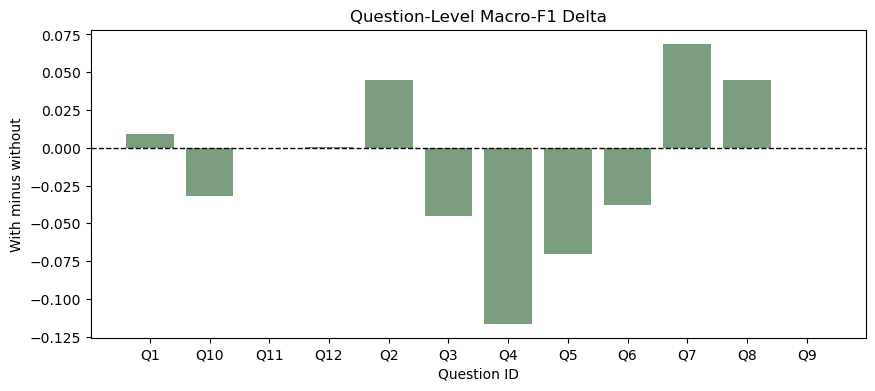

In [11]:

fig, ax = plt.subplots(figsize=(10, 4))
plot_df = question_results.sort_values("question_id")
ax.bar(plot_df["question_id"], plot_df["macro_f1_delta"], color="#7a9e7e")
ax.axhline(0.0, color="black", linewidth=1, linestyle="--")
ax.set_title("Question-Level Macro-F1 Delta")
ax.set_ylabel("With minus without")
ax.set_xlabel("Question ID")
plt.show()


## 8. Exploratory Secondary Metrics

In [12]:

secondary_metrics = [
    "direct_answer_token_f1",
    "rationale_token_f1",
    "evidence_support_ratio",
]
secondary_cluster = cluster_bootstrap.loc[secondary_metrics, [
    "mean_delta",
    "ci_lower",
    "ci_upper",
    "approx_two_sided_p",
]].round(4)
secondary_tests = question_tests.loc[secondary_metrics, [
    "mean_with",
    "mean_without",
    "mean_delta",
    "median_delta",
    "p_value",
    "effect_size",
    "direction",
]].round(4)
exact_match_df = pd.DataFrame([paired_stats["exact_match_test"]]).round(4)

display(secondary_cluster)
display(secondary_tests)
display(exact_match_df)


,mean_delta,ci_lower,ci_upper,approx_two_sided_p
direct_answer_token_f1,-0.0046,-0.0125,0.0044,0.2890
rationale_token_f1,-0.0063,-0.0153,0.0025,0.1665
evidence_support_ratio,-0.0006,-0.0132,0.0117,0.9560


,mean_with,mean_without,mean_delta,median_delta,p_value,effect_size,direction
direct_answer_token_f1,0.4742,0.4789,-0.0046,-0.0099,0.3301,-0.2882,higher_is_better
rationale_token_f1,0.3178,0.3241,-0.0063,-0.0028,0.2271,-0.3755,higher_is_better
evidence_support_ratio,0.9685,0.9691,-0.0006,0.0015,0.9326,-0.0226,higher_is_better


,with_rate,without_rate,delta,wins,losses,ties,discordant_pairs,sign_test_p_value,mcnemar_exact_p_value,effect_size,n_pairs,endpoint_role
0,0.7451,0.7549,-0.0098,13,15,176,28,0.8506,0.8506,-0.0264,204,exploratory_unclustered


## 8b. Confusion Matrices and Parse Failures

In [ ]:
import numpy as np

# --- Parse failure analysis ---
n_failures_with = summary["aggregate_metrics"]["with_esrs_context"]["n_failures"]
n_failures_without = summary["aggregate_metrics"]["without_esrs_context"]["n_failures"]
print(f"Parse failures: with_esrs_context={n_failures_with}, without_esrs_context={n_failures_without}")
if n_failures_without > 0:
    failure_rows = sample_results[
        (sample_results["condition"] == "without_esrs_context") & (sample_results["success"] == False)
    ][["question_id", "company", "error"]].reset_index(drop=True)
    display(failure_rows)

# --- Confusion matrices ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
labels = ["Low", "Medium", "High"]
for ax, condition in zip(axes, ["with_esrs_context", "without_esrs_context"]):
    cm = np.array(summary["aggregate_metrics"][condition]["confusion_matrix"])
    im = ax.imshow(cm, cmap="Blues", aspect="auto")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(3))
    ax.set_xticklabels(labels)
    ax.set_yticks(range(3))
    ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Gold")
    ax.set_title(condition.replace("_", " ").title())
plt.suptitle("Confusion Matrices: Gold vs Predicted Fulfillment Level", y=1.02)
plt.tight_layout()
plt.show()

# --- Per-label metrics ---
for condition in ["with_esrs_context", "without_esrs_context"]:
    plm = summary["aggregate_metrics"][condition].get("per_label_metrics", {})
    if plm:
        print(f"\n{condition}:")
        plm_df = pd.DataFrame(plm).T
        display(plm_df.round(4))

## 9. Descriptive Per-Standard Results

In [13]:

per_standard_rows = []
for condition, standard_map in summary["per_standard_metrics"].items():
    for standard, metrics in standard_map.items():
        per_standard_rows.append(
            {
                "condition": condition,
                "esrs_standard": standard,
                "macro_f1": metrics["macro_f1"],
                "balanced_accuracy": metrics["balanced_accuracy"],
                "exact_accuracy": metrics["exact_accuracy"],
                "weighted_kappa": metrics["weighted_kappa"],
                "ordinal_error_mean": metrics["ordinal_error_mean"],
            }
        )
per_standard_df = pd.DataFrame(per_standard_rows).sort_values(["esrs_standard", "condition"]).round(4)
per_standard_df


,condition,esrs_standard,macro_f1,balanced_accuracy,exact_accuracy,weighted_kappa,ordinal_error_mean
0,with_esrs_context,ESRS 2,0.3634,0.4636,0.6765,0.2890,0.3235
11,without_esrs_context,ESRS 2,0.3234,0.3580,0.6562,0.2072,0.3438
1,with_esrs_context,ESRS E1,0.4868,0.7115,0.8235,0.4632,0.1765
12,without_esrs_context,ESRS E1,0.5317,0.7500,0.8824,0.6047,0.1176
2,with_esrs_context,ESRS E2,0.3883,0.6286,0.5882,0.2323,0.4118
13,without_esrs_context,ESRS E2,0.5048,0.7571,0.7647,0.5143,0.2353
3,with_esrs_context,ESRS E3,0.7712,0.8889,0.8824,0.8468,0.1176
14,without_esrs_context,ESRS E3,0.8413,0.9167,0.9412,0.9209,0.0588
4,with_esrs_context,ESRS E4,0.4778,0.7167,0.7647,0.4333,0.2353
15,without_esrs_context,ESRS E4,0.5156,0.7583,0.8235,0.5487,0.1765


## 10. Resource Note

In [ ]:
resource_note = pd.DataFrame([
    {
        "n_question_contexts": len(context_df),
        "mean_estimated_tokens": round(context_df["estimated_tokens"].mean(), 1),
        "max_estimated_tokens": int(context_df["estimated_tokens"].max()),
        "condition_parallelism": summary.get("condition_parallelism", "n/a"),
        "model": summary.get("model", "n/a"),
        "temperature": summary.get("temperature", "n/a"),
    }
])
resource_note

## 11. Thesis Claim Logic

In [ ]:
primary_ci = paired_stats["cluster_bootstrap"]["macro_f1"]
primary_test = paired_stats["question_level_tests"]["macro_f1"]

if primary_test["p_value"] < 0.05 and primary_ci["ci_lower"] > 0:
    verdict = "statistically defensible improvement"
elif primary_test["p_value"] < 0.05 and primary_ci["ci_upper"] < 0:
    verdict = "statistically defensible degradation"
else:
    verdict = "no statistically defensible difference"

# Count metric directions
n_favor_with = sum(
    1 for m in ["macro_f1", "balanced_accuracy", "exact_accuracy", "weighted_kappa"]
    if paired_stats["question_level_tests"][m]["mean_delta"] > 0
)
n_favor_without = 4 - n_favor_with

claim_md = f"""
**Primary endpoint:** question-level macro-F1 delta (`with_esrs_context` minus `without_esrs_context`).

- Mean delta: **{primary_test['mean_delta']:.4f}**
- 95% question-cluster bootstrap CI: **[{primary_ci['ci_lower']:.4f}, {primary_ci['ci_upper']:.4f}]**
- Paired sign test p-value across 12 question deltas: **{primary_test['p_value']:.4f}**
- Effect size (Cohen's d): **{primary_test['effect_size']:.4f}**
- Classification metrics favoring WITH: **{n_favor_with}/4**, favoring WITHOUT: **{n_favor_without}/4**
- Primary interpretation: **{verdict}**

**Thesis-safe conclusion:** The paired ablation study finds no statistically significant
difference in classification performance between the condition that injects the full
ESRS standard and the condition that omits it (macro-F1 delta = {primary_test['mean_delta']:.3f},
95% CI [{primary_ci['ci_lower']:.3f}, {primary_ci['ci_upper']:.3f}], p = {primary_test['p_value']:.3f}).
The LLM's parametric knowledge of ESRS appears sufficient for compliance classification
at the observed performance level. The ESRS injection does not measurably improve or
degrade accuracy, suggesting that the retrieved company report evidence — not the
regulatory text — is the binding constraint on classification quality.

**Limitations of this null result:**
- 12 questions provide low statistical power (the sign test with n=12 can only detect
  large effects). A true small effect may exist but be undetectable at this sample size.
- The 3 parse failures in the without-context condition (3/204 = 1.5%) are excluded from
  paired analysis. All occurred in the same condition, possibly indicating that ESRS
  context helps the model produce well-formed outputs, but the effect is too small to
  change the aggregate conclusion.
- The class imbalance (71% High) means the system can achieve high exact accuracy by
  defaulting to High; macro-F1 and balanced accuracy are the appropriate metrics here.
"""

display(Markdown(claim_md))